# Model V3: Predicting Customer Dissatisfaction (Classification)

### Previous Findings:
- **Model A (Environment Only):** R2 ~ 0.21. Logistics (delays, distance) explain about 21% of the variance.
- **Model B (Full Context):** R2 ~ 0.24. Adding Seller/Location data only marginally improved the *regression* performance.
- **Conclusion:** The exact `review_score` (1-5) is too noisy for precise regression. However, the data clearly separates "Happy" (4-5) from "Unhappy" (1-3) customers.

### Current Objective:
We are shifting to a **Binary Classification** task. 
- **Target:** `is_dissatisfied` (1 if `review_score` < 4, else 0).
- **Goal:** Build a "Red Flag" detector that alerts Olist when an order is likely to result in poor satisfaction based on the product, seller, and logistics situation.

In [5]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from xgboost import XGBClassifier
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, roc_curve
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load Data
df = pd.read_csv('../../datasets/processed/olist_reviews_rich.csv')

# 2. Define Target: Dissatisfaction (Score 1, 2, 3)
df['is_dissatisfied'] = (df['review_score'] < 4).astype(int)
print(f"Class Distribution:\n{df['is_dissatisfied'].value_counts(normalize=True)}")

# 3. Feature Engineering
df['log_price'] = np.log1p(df['price'])
df['log_distance'] = np.log1p(df['distance_km'])
df['delivery_delta'] = df['actual_delivery_days'] - df['estimated_delivery_days']

features = [
    'actual_delivery_days', 'delivery_delta', 'is_late', 'log_distance', 
    'log_price', 'freight_value', 'seller_state', 'customer_state', 
    'seller_total_orders', 'product_weight_g', 'n_items'
]

X = df[features].copy()
y = df['is_dissatisfied']

# Fill NaNs
numeric_cols = X.select_dtypes(include=[np.number]).columns
X[numeric_cols] = X[numeric_cols].fillna(X[numeric_cols].median())
X = X.fillna('Unknown')

# Encode Categoricals
le = LabelEncoder()
X['seller_state'] = le.fit_transform(X['seller_state'].astype(str))
X['customer_state'] = le.fit_transform(X['customer_state'].astype(str))

# 4. Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print(f"\nTraining features: {X.columns.tolist()}")

Class Distribution:
is_dissatisfied
0    0.789089
1    0.210911
Name: proportion, dtype: float64

Training features: ['actual_delivery_days', 'delivery_delta', 'is_late', 'log_distance', 'log_price', 'freight_value', 'seller_state', 'customer_state', 'seller_total_orders', 'product_weight_g', 'n_items']


## 1. Train XGBoost Classifier (Balanced)

Since dissatisfied customers are the minority (~20%), we use `scale_pos_weight` to help the model focus on them.

In [6]:
# Calculate scale_pos_weight
ratio = float(y_train.value_counts()[0]) / y_train.value_counts()[1]

xgb_clf = XGBClassifier(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=6,
    scale_pos_weight=ratio, # Critical for imbalance
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    use_label_encoder=False,
    eval_metric='auc'
)

xgb_clf.fit(X_train, y_train)

# Predictions
y_pred = xgb_clf.predict(X_test)
y_prob = xgb_clf.predict_proba(X_test)[:, 1]

print("Classification Report:")
print(classification_report(y_test, y_pred))
print(f"ROC-AUC Score: {roc_auc_score(y_test, y_prob):.4f}")

C:\Users\Devyansh\AppData\Roaming\Python\Python312\site-packages\xgboost\training.py:183: UserWarning: [00:08:05] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


Classification Report:
              precision    recall  f1-score   support

           0       0.86      0.82      0.84     15049
           1       0.42      0.50      0.46      4022

    accuracy                           0.75     19071
   macro avg       0.64      0.66      0.65     19071
weighted avg       0.77      0.75      0.76     19071

ROC-AUC Score: 0.7128


## 2. Visualize Performance

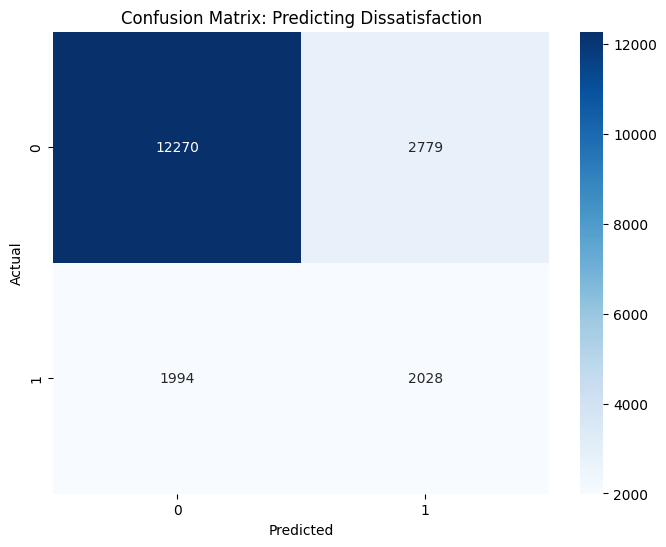

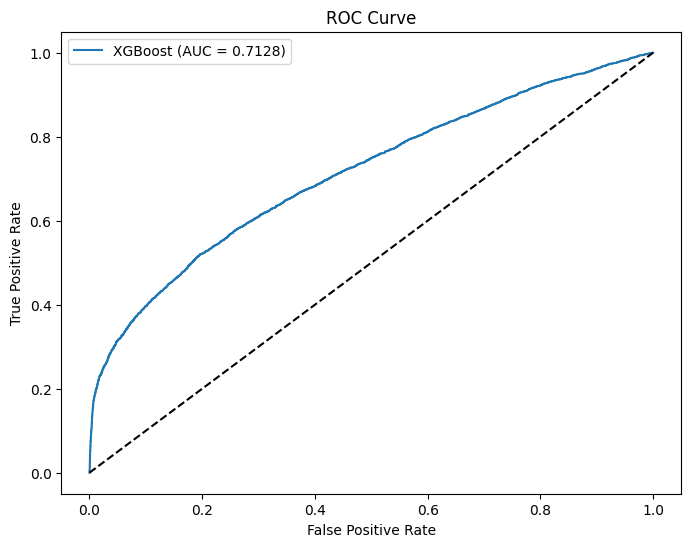

In [7]:
# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix: Predicting Dissatisfaction')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

# ROC Curve
fpr, tpr, _ = roc_curve(y_test, y_prob)
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label=f'XGBoost (AUC = {roc_auc_score(y_test, y_prob):.4f})')
plt.plot([0, 1], [0, 1], 'k--')
plt.title('ROC Curve')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend()
plt.show()

## 3. Top Risk Factors

Which factors most strongly predict that a customer will be unhappy?

C:\Users\Devyansh\AppData\Local\Temp\ipykernel_26364\1854974257.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importance', y='Feature', data=importance_df, palette='magma')


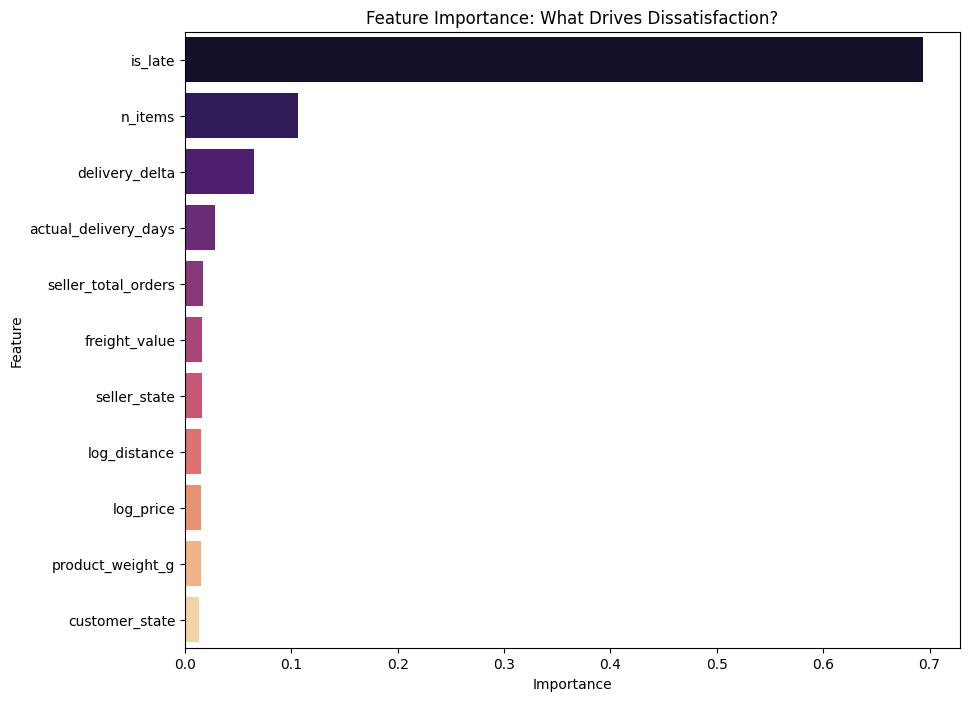

In [8]:
importance_df = pd.DataFrame({
    'Feature': features,
    'Importance': xgb_clf.feature_importances_
}).sort_values(by='Importance', ascending=False)

plt.figure(figsize=(10, 8))
sns.barplot(x='Importance', y='Feature', data=importance_df, palette='magma')
plt.title('Feature Importance: What Drives Dissatisfaction?')
plt.show()